# 14 · Profile importance sampling step by step

**Level:** advanced · **Prerequisites:** [12](12_importance_sampling_from_scratch.ipynb), [13](13_why_b_is_hard.ipynb) · **Run time:** ~30 s (~15 s with `PIZZETTI_SMOKE=1`)

**Covers:** the profile proposal along b (`pizzetti._sampling.profile_is`): the posterior maximum, the adaptive grid of conditional optima, the Laplace profile ℓ(b), the Student-t conditionals, the weights and their diagnostics, stage 2, defensive draws and grid refinement; `MarginalTransitModel.profile_is` and `fit()`; accuracy against emcee

Notebook 13 showed that a Gaussian proposal cannot follow the posterior of a transit along b. Profile importance
sampling builds the proposal *along* b instead: for each value of b on a grid, the other parameters are close to
Gaussian, so their conditional mean and covariance are all a proposal needs, and the marginal density of b itself
comes from the same conditional fits. This is what `MarginalTransitModel.fit()` runs. Here we take it apart.

In [1]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pizzetti
from pizzetti._sampling import profile_is

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"
warnings.filterwarnings("ignore", category=RuntimeWarning)

## Data (identical to notebooks 02, 03 and 06)

In [2]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=0.40, u2=0.25)
sigma = 500e-6
t_one = np.arange(-0.13, 0.13, 2.0 / 1440)
t = (np.arange(7)[:, None] * truth["per"] + t_one[None, :]).ravel()
p_true = pizzetti.TransitParams()
p_true.t0, p_true.per, p_true.rp, p_true.a = truth["t0"], truth["per"], truth["rp"], truth["a"]
p_true.inc = np.degrees(np.arccos(truth["b"] / truth["a"]))
p_true.ecc, p_true.w, p_true.limb_dark, p_true.u = 0.0, 90.0, "quadratic", [truth["u1"], truth["u2"]]
f_true = pizzetti.TransitModel(p_true, t, series_tol=0.0, limb="quadrature").light_curve(p_true)
y = f_true + sigma * np.random.default_rng(42).standard_normal(t.size)
model = pizzetti.MarginalTransitModel(p_true, t, y, sigma, free=["t0", "per", "rp", "a", "b"],
                                      bounds={"rp": (0, 0.5), "a": (1.5, 100)})

## The sampler's coordinates

The sampler works in *internal* coordinates, `model.log_prob_internal(X)`: the same parameters, except that a
circular orbit uses the transit duration T₁₄ instead of a/R★ (`model.t14`), which removes most of the b–a/R★
curvature. `model.to_internal` and `model.to_physical` convert, and `model._default_scales` gives rough
scales for the optimiser.

In [3]:
x0 = model.to_internal(model.fixed_physical_free())[0]           # start: the TransitParams values
scale = model._default_scales(x0)
jb = model.free.index("b")
print("free:", model.free, "| T14 instead of a/R*:", model.t14)
print("start (internal):", np.round(x0, 5))

free: ['t0', 'per', 'rp', 'a', 'b'] | T14 instead of a/R*: True
start (internal): [0.      3.5     0.1     0.12948 0.35   ]


## Steps 1–4 in one call

`profile_is(log_prob, x0, scale, prof=jb, ...)` runs the whole construction:

1. **Maximum.** Locate the maximum of the log posterior.
2. **Profile.** On a grid in b that starts at the maximum and grows geometrically in both directions, maximise
   over the other parameters and take their Hessian. Each grid point gives the conditional mean μ(b), the
   conditional covariance Σ(b), and the Laplace marginal ℓ(b) = max log p(b, ·) + ½ log|Σ(b)|. The grid stops
   where ℓ has fallen 12 nats below its peak, or at a wall (`lo_wall=0`: b = 0).
3. **Proposal.** b from the piecewise-linear density ∝ e^ℓ(b) on the grid; the other parameters from a
   Student-t (5 degrees of freedom) with mean and covariance interpolated in b, inflated by 1.2.
4. **Weights.** Exact posterior over proposal density, Pareto-smoothed (notebook 12).

In [4]:
n_draws = 4000                                        # fit()'s default
t_start = time.perf_counter()
res = profile_is(model.log_prob_internal, x0, scale, prof=jb, n=n_draws, rng=np.random.default_rng(1), lo_wall=1e-9)
wall_is = time.perf_counter() - t_start
print(f"{res['n_eval']:,} evaluations ({res['n_eval_map']:,} for the maximum), {wall_is:.1f} s")
print(f"grid: {res['n_grid']} points, complete: {res['complete']}, refinements: {res['n_refine']}")
print(f"k-hat {res['khat']:.2f}, ESS {res['ess']:.0f} of {len(res['w'])} draws, stage {res['stage']}")

13,523 evaluations (660 for the maximum), 0.4 s
grid: 17 points, complete: True, refinements: 0
k-hat 0.17, ESS 2965 of 4400 draws, stage 1


## The profile

Each grid point is a conditional optimisation (most of the cost). The profile ℓ(b) combines the height of the
conditional maximum with the width of the conditional posterior: where the other parameters are less tightly
constrained, more posterior volume sits at that b.

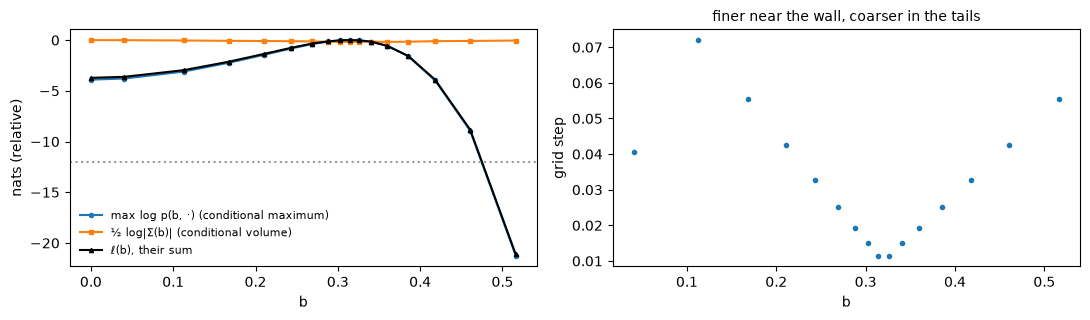

In [5]:
gb, gl = res["grid_b"], res["grid_logdens"]
lpmax, logdet = res["grid_lpmax"], res["grid_logdet"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(gb, lpmax - lpmax.max(), "o-", ms=3, label="max log p(b, ·) (conditional maximum)")
ax[0].plot(gb, 0.5 * (logdet - logdet.max()), "s-", ms=3, label="½ log|Σ(b)| (conditional volume)")
ax[0].plot(gb, gl - gl.max(), "k^-", ms=3, label="ℓ(b), their sum")
ax[0].axhline(-12, color="0.6", ls=":"); ax[0].set_xlabel("b"); ax[0].set_ylabel("nats (relative)")
ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(gb, np.r_[np.nan, np.diff(gb)], "o", ms=3)
ax[1].set_xlabel("b"); ax[1].set_ylabel("grid step"); ax[1].set_title("finer near the wall, coarser in the tails", fontsize=10)
fig.tight_layout()

## Proposal against posterior

For a reference we run emcee on the same marginal posterior until convergence (as in notebook 13), which also
gives its cost, and then continue the chain to 20 000 steps: a chain of 50 autocorrelation times still carries
noticeable Monte Carlo noise in the tails (notebook 16). The proposal density of b, the weighted draws and the
reference agree; the conditional mean of a/R★ given b follows the curved ridge.

emcee to convergence: 144,032 evaluations, 3.3 s, max tau 86 steps


reference: 20000 steps, 626,208 draws


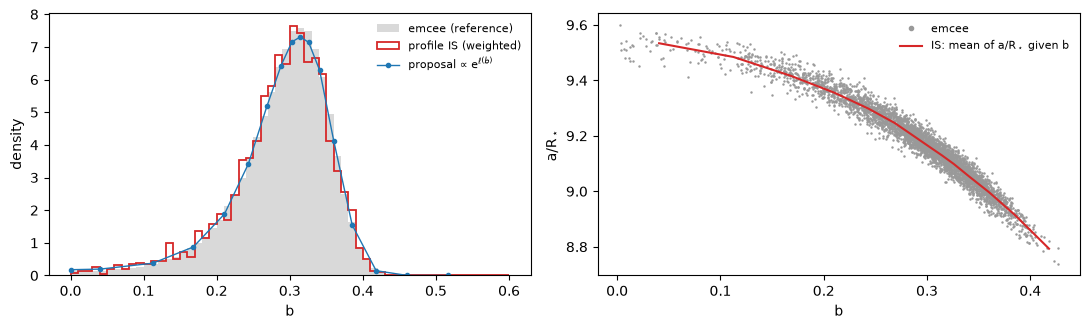

In [6]:
def run_to_convergence(sampler, p0, ntau=(10 if SMOKE else 50), check=500, max_steps=200_000, seed=2024):
    # emcee in chunks of `check` steps until the chain is ntau autocorrelation times long and tau is stable
    sampler.random_state = np.random.RandomState(seed).get_state()
    state, old = p0, np.inf
    while sampler.iteration < max_steps:
        state = sampler.run_mcmc(state, check, progress=False)
        tau = sampler.get_autocorr_time(tol=0)
        if np.all(ntau * tau < sampler.iteration) and np.all(np.abs(old - tau) / tau < 0.01):
            break
        old = tau
    tau = sampler.get_autocorr_time(tol=0)
    return dict(steps=sampler.iteration, tau=tau, burn=int(5 * tau.max()))

x_true = np.array([truth["t0"], truth["per"], truth["rp"], truth["a"], truth["b"]])
p0 = x_true + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02]) * np.random.default_rng(1).standard_normal((32, 5))
model.n_eval = 0
sampler = model.EnsembleSampler(32)
t_start = time.perf_counter()
mc = run_to_convergence(sampler, p0)
wall_mc = time.perf_counter() - t_start
evals_mc = model.n_eval
print(f"emcee to convergence: {evals_mc:,} evaluations, {wall_mc:.1f} s, max tau {mc['tau'].max():.0f} steps")
n_ref = 0 if SMOKE else 20_000 - sampler.iteration              # continue the chain for the reference
if n_ref > 0:
    sampler.run_mcmc(sampler.get_last_sample(), n_ref, progress=False)   # an emcee State: no conversion
ref = sampler.get_chain(discard=mc["burn"], flat=True, seed=1)
lab = list(sampler.labels)
print(f"reference: {sampler.iteration} steps, {len(ref):,} draws")

X = model.to_physical(res["theta"])                   # physical coordinates: t0, per, rp, a, b
w = res["w"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(0, 0.6, 61)
ax[0].hist(ref[:, lab.index("b")], bins=bins, density=True, histtype="stepfilled", color="0.85", label="emcee (reference)")
ax[0].hist(X[:, jb], bins=bins, weights=w, density=True, histtype="step", color="C3", lw=1.3, label="profile IS (weighted)")
pb = np.exp(gl - gl.max()); pb /= np.trapezoid(pb, gb)
ax[0].plot(gb, pb, "o-", color="C0", ms=3, lw=1, label="proposal ∝ e$^{ℓ(b)}$")
ax[0].set_xlabel("b"); ax[0].set_ylabel("density"); ax[0].legend(frameon=False, fontsize=8)
sel = np.random.default_rng(2).choice(len(ref), min(4000, len(ref)), replace=False)
ax[1].plot(ref[sel, lab.index("b")], ref[sel, lab.index("a")], ".", ms=1.5, color="0.6", label="emcee")
cm = [(bv, np.average(X[np.abs(X[:, jb] - bv) < 0.01, 3], weights=w[np.abs(X[:, jb] - bv) < 0.01]))
      for bv in gb if np.sum(np.abs(X[:, jb] - bv) < 0.01) > 20]
cm = np.array(cm)
ax[1].plot(cm[:, 0], cm[:, 1], "C3-", lw=1.5, label="IS: mean of a/R$_\\star$ given b")
ax[1].set_xlabel("b"); ax[1].set_ylabel("a/R$_\\star$"); ax[1].legend(frameon=False, fontsize=8, markerscale=4)
fig.tight_layout()

## The weights

A good proposal gives nearly uniform weights; k̂ and the ESS summarise them. Where they are large, the proposal is
too thin. Below: the weights against b, and the cumulative share of the largest weights.

k-hat 0.17; largest single weight 4.81e-04 (2.1 x the average)


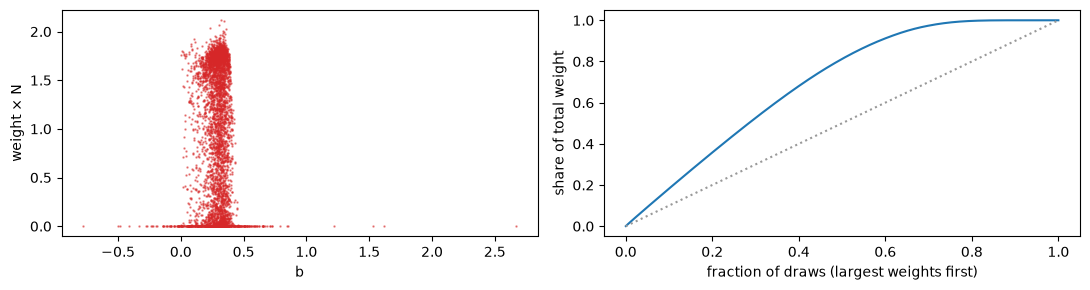

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(X[:, jb], w * len(w), ".", ms=1.5, color="C3", alpha=0.5)
ax[0].set_xlabel("b"); ax[0].set_ylabel("weight × N")
ws = np.sort(w)[::-1]
ax[1].plot(np.arange(1, len(ws) + 1) / len(ws), np.cumsum(ws))
ax[1].plot([0, 1], [0, 1], color="0.6", ls=":")
ax[1].set_xlabel("fraction of draws (largest weights first)"); ax[1].set_ylabel("share of total weight")
fig.tight_layout()
print(f"k-hat {res['khat']:.2f}; largest single weight {ws[0]:.2e} ({ws[0] * len(w):.1f} x the average)")

## Steps 5–7: stage 2, defensive draws, refinement

The construction has three safeguards for proposals that are not good enough:

5. **Stage 2.** If k̂ ≥ 0.5 after the first draws, a second batch comes from a mixture of the profile proposal and
   a Student-t fitted to the weighted first-stage draws, and all draws are weighted against the combined
   proposal (`res["stage"]` says which stage was used).
6. **Defensive draws.** A further 10% of draws come from a broad Student-t (twice the standard deviation of the
   weighted draws), so that a proposal that stops short of part of the posterior produces large weights there,
   which k̂ sees (notebook 12, section 4).
7. **Grid refinement.** If the final k̂ is still ≥ 0.7, midpoints are added to the grid wherever the
   interpolated conditional mean is off by more than 0.25 conditional standard deviations, and the draws are
   repeated.

Here stage 1 sufficed and no refinement was needed. Notebook 15 shows what happens when the profile itself is not
enough.

## The model's wrapper and `fit()`

`model.profile_is()` adds the walls of b from the bounds, a start inside the prior, and the further attempts of
notebook 15. `fit()` calls it, draws the limb-darkening coefficients for every draw ([06](06_marginal_transit_model.ipynb)),
and returns a `FitResult`.

In [8]:
result = model.fit(seed=1, n=8000)
d = result.diagnostics
print(f"method {d['method']}, k-hat {d['khat']:.2f}, ESS {d['ess']:.0f}, complete {d['complete']}, "
      f"n_grid {d['n_grid']}, is_ok {d['is_ok']}")
print(result.labels)

method profile-IS, k-hat -0.19, ESS 5952, complete True, n_grid 17, is_ok True
['t0', 'per', 'rp', 'a', 'b', 'q1', 'q2', 'f0']


## How accurate, and how fast?

The paper's accuracy measure: the 2.5, 16, 50, 84 and 97.5% quantiles of every parameter, IS against the
reference, in units of the reference posterior standard deviation; the largest difference over all parameters
and quantiles. Two emcee chains of the same length differ from each other by a similar amount (notebook 16).

In [9]:
def wquantiles(x, w, qs=(0.025, 0.16, 0.5, 0.84, 0.975)):
    o = np.argsort(x)
    cw = np.cumsum(w[o]); cw /= cw[-1]
    return np.interp(qs, cw - 0.5 * w[o] / w.sum(), x[o])

dev = {}
for j, q in enumerate(model.free):
    r_ = ref[:, lab.index(q)]
    dev[q] = np.max(np.abs(wquantiles(X[:, j], w) - np.quantile(r_, (0.025, 0.16, 0.5, 0.84, 0.975)))) / r_.std()
print("largest quantile difference (sd):", {q: round(float(v), 3) for q, v in dev.items()})
print(f"P(b < 0.15): IS {np.sum(w[X[:, jb] < 0.15]):.4f}, emcee {np.mean(ref[:, lab.index('b')] < 0.15):.4f}")
print(f"evaluations: IS {res['n_eval']:,} ({len(w)} draws), emcee {evals_mc:,}  ->  {evals_mc / res['n_eval']:.0f}x fewer")
print(f"wall time:   IS {wall_is:.1f} s, emcee {wall_mc:.1f} s")

largest quantile difference (sd): {'t0': 0.017, 'per': 0.031, 'rp': 0.058, 'a': 0.088, 'b': 0.154}
P(b < 0.15): IS 0.0486, emcee 0.0394
evaluations: IS 13,523 (4400 draws), emcee 144,032  ->  11x fewer
wall time:   IS 0.4 s, emcee 3.3 s


## What you learned

- The profile proposal is built from conditional optima along b: μ(b), Σ(b) and the Laplace marginal ℓ(b), on an
  adaptive grid that stops 12 nats down or at the wall.
- b is drawn from e^ℓ(b), the other parameters from interpolated Student-t conditionals; Pareto-smoothed weights
  correct the rest.
- Stage 2, defensive draws and grid refinement guard the proposal; `fit()` wraps all of it.
- Against a converged emcee run, the posterior agrees within the Monte Carlo noise, at a fraction of the cost.

**Next:** [14 · When the profile is not enough](15_when_the_profile_is_not_enough.ipynb)